<a href="https://colab.research.google.com/github/Simpson69-il/DEEPLEARNING5THSEM/blob/main/EXERCISE_6/EX6_LSTM_Sentiment_Analysis_24BAD074.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 6: Implementation of LSTM for Sentiment Analysis

**Name:** Mohd Shafique R B  
**Roll No:** 24BAD074  

Run the cells from top to bottom in Google Colab. Outputs are generated when you run the notebook; capture screenshots for the corresponding lab-report sections.

## Part A: Dataset preparation
This notebook uses the IMDB movie-review dataset provided by Keras. Reviews are supplied as integer-encoded token sequences, so the notebook pads them to a common length and creates training, validation, and test sets.

In [1]:
# Mohd Shafique R B | Roll No: 24BAD074
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

VOCAB_SIZE = 10000
MAX_LEN = 200
BATCH_SIZE = 128
EPOCHS = 5

(x_train_all, y_train_all), (x_test, y_test) = imdb.load_data(num_words=VOCAB_SIZE)
x_train_all = pad_sequences(x_train_all, maxlen=MAX_LEN, padding="post", truncating="post")
x_test = pad_sequences(x_test, maxlen=MAX_LEN, padding="post", truncating="post")

x_val, y_val = x_train_all[:5000], y_train_all[:5000]
x_train, y_train = x_train_all[5000:], y_train_all[5000:]

print("ROLL NO: 24BAD074")
print("Training shape:", x_train.shape)
print("Validation shape:", x_val.shape)
print("Test shape:", x_test.shape)
print("Sample review sequence:", x_train[0][:40])
print("Sentiment label (0=negative, 1=positive):", int(y_train[0]))
print("Class counts in training data:", np.bincount(y_train))

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
ROLL NO: 24BAD074
Training shape: (20000, 200)
Validation shape: (5000, 200)
Test shape: (25000, 200)
Sample review sequence: [   1   13  104   14 2856   77    6  542   20    5   49    7   94  531
   26  608   21   11  226   45    6  503   20  172   44    4  114  531
   26  608   21   12   47  450 1512    5    2   15  152  179]
Sentiment label (0=negative, 1=positive): 0
Class counts in training data: [10046  9954]


## Part B: Implementing the LSTM model

In [2]:
# Mohd Shafique R B | Roll No: 24BAD074
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

model = Sequential([
    Embedding(input_dim=VOCAB_SIZE, output_dim=64),
    LSTM(64, dropout=0.2),
    Dropout(0.3),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("ROLL NO: 24BAD074")
model.summary()

ROLL NO: 24BAD074


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

## Part C: Model training and performance evaluation
This cell trains the model, evaluates it on the test set, prints precision/recall/F1, and displays a confusion matrix and learning curves.

Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 60s 338ms/step - accuracy: 0.5185 - loss: 0.6908 - val_accuracy: 0.6428 - val_loss: 0.6622
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 81s 333ms/step - accuracy: 0.5716 - loss: 0.6791 - val_accuracy: 0.5328 - val_loss: 0.6830
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 52s 332ms/step - accuracy: 0.6187 - loss: 0.6454 - val_accuracy: 0.7012 - val_loss: 0.6196
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 51s 327ms/step - accuracy: 0.6951 - loss: 0.6044 - val_accuracy: 0.5464 - val_loss: 0.6756
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 50s 321ms/step - accuracy: 0.6981 - loss: 0.5799 - val_accuracy: 0.7162 - val_loss: 0.5752
ROLL NO: 24BAD074
Training accuracy (last epoch): 0.6981
Validation accuracy (last epoch): 0.7162
Training loss (last epoch): 0.5799
Validation loss (last epoch): 0.5752
Test loss: 0.5809
Test accuracy: 0.7114

Classification report:
              precision    recall  f1-score   support

    Negative       0.66      0.86      0.75     12500
    Pos

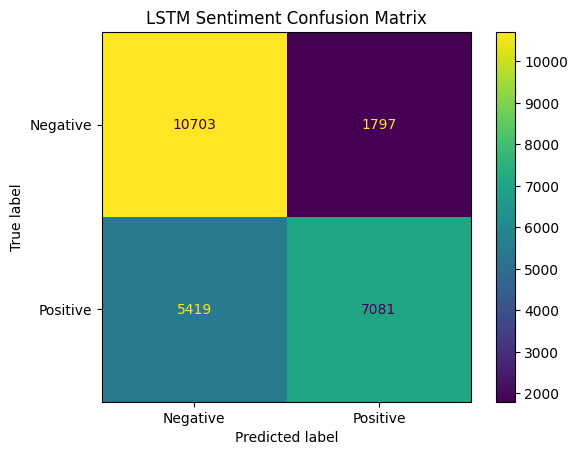

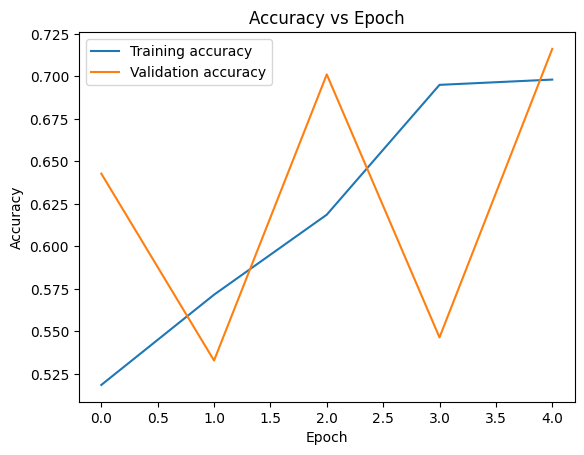

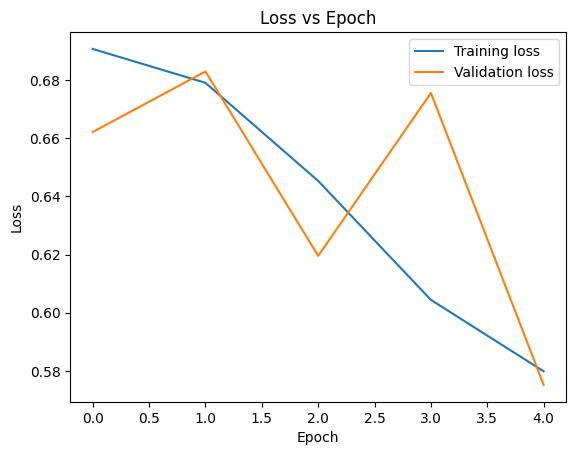

In [3]:
# Mohd Shafique R B | Roll No: 24BAD074
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

history = model.fit(
    x_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(x_val, y_val),
    verbose=1
)

test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
probabilities = model.predict(x_test, verbose=0).ravel()
predictions = (probabilities >= 0.5).astype(int)

print("ROLL NO: 24BAD074")
print(f"Training accuracy (last epoch): {history.history['accuracy'][-1]:.4f}")
print(f"Validation accuracy (last epoch): {history.history['val_accuracy'][-1]:.4f}")
print(f"Training loss (last epoch): {history.history['loss'][-1]:.4f}")
print(f"Validation loss (last epoch): {history.history['val_loss'][-1]:.4f}")
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print("\nClassification report:")
print(classification_report(y_test, predictions, target_names=["Negative", "Positive"]))

cm = confusion_matrix(y_test, predictions)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Negative", "Positive"]).plot()
plt.title("LSTM Sentiment Confusion Matrix")
plt.show()

plt.figure()
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy vs Epoch")
plt.legend()
plt.show()

plt.figure()
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss vs Epoch")
plt.legend()
plt.show()

## Part D: Sentiment prediction
The IMDB dataset uses a predefined word index. This helper converts simple review text into the same index format and predicts sentiment. The small example vocabulary mapping is approximate because Keras' IMDB word index is based on individual tokens and frequency ranks.

In [4]:
# Mohd Shafique R B | Roll No: 24BAD074
word_index = imdb.get_word_index()

def encode_review(text):
    sequence = [1]  # IMDB start token
    for word in text.lower().split():
        # Keras IMDB reserves indices 0-3 for padding/start/unknown/unused.
        index = word_index.get(word)
        sequence.append(index + 3 if index is not None and index + 3 < VOCAB_SIZE else 2)
    return pad_sequences([sequence], maxlen=MAX_LEN, padding="post", truncating="post")

reviews = [
    ("This movie was wonderful and the acting was excellent", "Expected positive"),
    ("This film was boring and terrible and I did not enjoy it", "Expected negative"),
    ("The story was good and the characters were lovely", "Expected positive"),
    ("A bad movie with a weak story and poor acting", "Expected negative")
]

print("ROLL NO: 24BAD074")
for review, expected in reviews:
    sequence = encode_review(review)
    probability = float(model.predict(sequence, verbose=0)[0][0])
    predicted = "Positive" if probability >= 0.5 else "Negative"
    print("\nReview:", review)
    print("Expected:", expected)
    print(f"Predicted: {predicted} (positive probability = {probability:.4f})")

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
ROLL NO: 24BAD074

Review: This movie was wonderful and the acting was excellent
Expected: Expected positive
Predicted: Negative (positive probability = 0.3796)

Review: This film was boring and terrible and I did not enjoy it
Expected: Expected negative
Predicted: Negative (positive probability = 0.3796)

Review: The story was good and the characters were lovely
Expected: Expected positive
Predicted: Negative (positive probability = 0.3796)

Review: A bad movie with a weak story and poor acting
Expected: Expected negative
Predicted: Negative (positive probability = 0.3796)


## Observation
After running the notebook, record the actual training/validation accuracy and loss, test accuracy, classification metrics, confusion matrix, and sample predictions in the report. Values depend on training and runtime conditions.